In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

TRIVIA_QA_PATH = os.getenv('TRIVIA_QA_PATH')
Natural_Questions_PATH = os.getenv('Natural_Questions_PATH')
SQUAD_PATH = os.getenv('SQUAD_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [3]:
from knowledge_maze.create_dataset.load_datasets import load_data
load_data(f"{REPO_PATH}\data_files\extracted_data.json")

Processing SQuAD: 100%|████████████████████████████████████████████████████████████| 442/442 [00:00<00:00, 1002.85it/s]


Loaded 272007 question-answer pairs in total.


In [2]:
# Load from saved dataset:
extracted_data = load_json(f"{REPO_PATH}\data_files\extracted_data.json")

# 2. Data preprocess:
- Filter out problematic questions (long answers, answers within questions, complex questions)
- Classify answers by types of entities
- Update entity types in the dataset

Filtering WH questions: 100%|██████████████████████████████████████████████| 272007/272007 [00:00<00:00, 402739.36it/s]


244638 out of 272007 samples have passed (89.9%).


Filtering self containing questions: 100%|█████████████████████████████████| 244638/244638 [00:02<00:00, 103866.64it/s]


242584 out of 244638 samples have passed (99.2%).


Filtering out long questions: 100%|███████████████████████████████████████| 242584/242584 [00:00<00:00, 1746131.87it/s]


...

9038 numerical samples found (4.0%).


Extracting date & time samples: 100%|██████████████████████████████████████| 226408/226408 [00:00<00:00, 537909.90it/s]


22159 date & time samples found (9.8%).


Extracting rest of the relevant samples: 100%|████████████████████████████| 226408/226408 [00:00<00:00, 3219511.80it/s]


105584 relevant samples found (46.6%).
Generating pie chart...


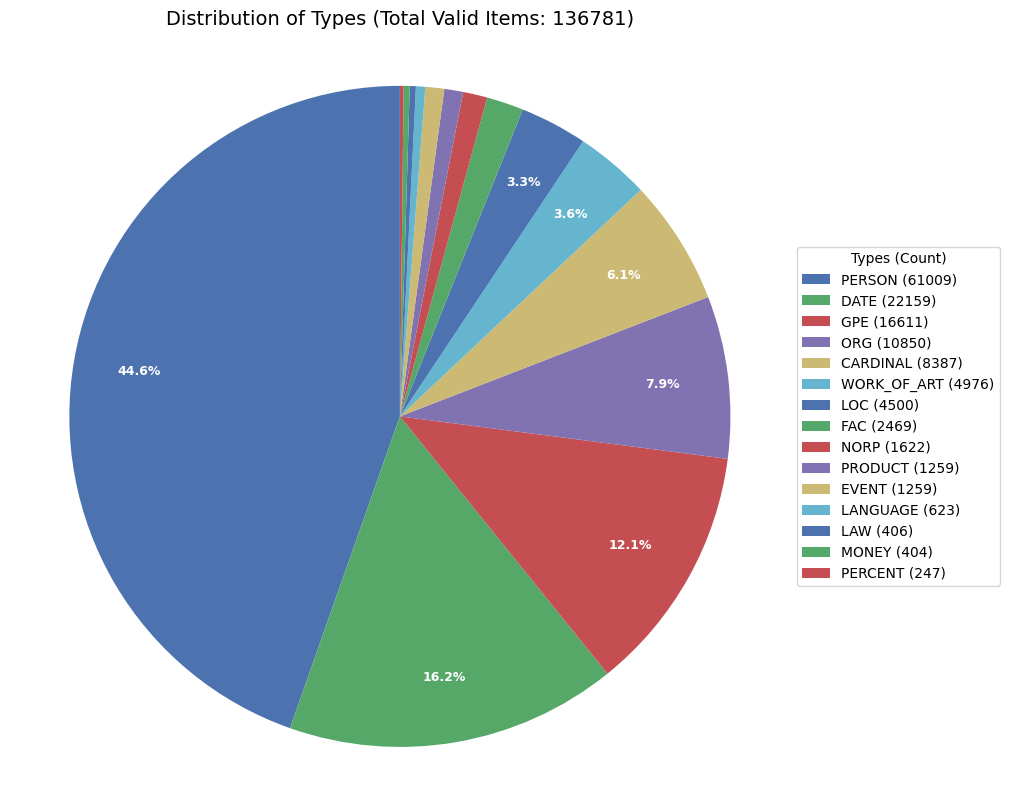

In [3]:
from knowledge_maze.create_dataset.preprocess import preprocess
processed_data = preprocess(extracted_data, output_path=f"{REPO_PATH}\data_files\processed_data.json")

In [2]:
# Load from saved dataset:
processed_data = load_json(f"{REPO_PATH}\data_files\processed_data.json")

# 3. Group questions:
- Group Questions togather based on shared answers
- Questions with numerical and date answers are grouped by closed value answers instead of exact match
- Filter out questions that are too semantically similar
- Filter out ambiguous questions
- Create candidate reasoning chains for the dataset

In [8]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
test_data = await create_paths(processed_data)

Dividing data by type...
Clustering data...
Creating reasoning paths for general clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.45s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████████| 72/72 [00:00<00:00, 2022.27it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████████████████████| 72/72 [00:00<?, ?it/s]


Creating reasoning paths for numerical clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 5/5 [00:13<00:00,  2.78s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 42/42 [00:06<00:00,  6.20it/s]
Splitting large clusters: 100%|█████████████████████████████████████████████████████| 42/42 [00:00<00:00, 13539.37it/s]


Creating reasoning paths for date clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 11/11 [00:31<00:00,  2.89s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 1106/1106 [00:06<00:00, 171.29it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1106/1106 [00:00<00:00, 174178.66it/s]


### TODOS - create reasoning path:
- remove numericals of value 0 
- change numerical group division based on similarity
- change plot distribution to adjust to the changes
- fix create reasoning path docstring

### TODOS - structure data:
- structure files in an organized way
- change the reasoning path seperation to be for 2 paths with at most 5 questions - need to see how to lose little questions as possible
- make new annotation before continue
- in paragraph creation need to think of a way to make it case sensitive, or make a prompt with reasoning process...

In [13]:
import faiss
import numpy as np
from collections import defaultdict
import math # For ceil
from typing import List, Dict, Optional

def cluster_sentences_kmeans_simple(
    sentences: List[str],
    embeddings_dict: Dict[str, np.ndarray],
    min_cluster_size: int,
    max_cluster_size: int,
    n_iterations: int = 20, # Number of K-Means iterations
) -> Optional[List[List[str]]]:
    """
    Clusters sentences using FAISS K-Means (simplified version).

    Estimates k, runs K-Means, and returns clusters. Does not enforce size limits.

    Args:
        sentences: An ordered list of sentence strings.
        embeddings_dict: Dict mapping sentences to their embedding vectors.
        min_cluster_size: Minimum *desired* size (used to estimate k).
        max_cluster_size: Maximum *desired* size (used to estimate k).
        n_iterations: Number of iterations for K-Means.

    Returns:
        A list of lists (clusters of sentences), or None on critical error.
    """
    # Basic input validation
    if not sentences or not embeddings_dict or min_cluster_size < 1 or min_cluster_size > max_cluster_size:
        print("Error: Invalid input (empty data or invalid size constraints).")
        return None

    # 1. Prepare embeddings array and track valid sentences corresponding to rows
    embeddings_list = []
    valid_sentences = []
    embedding_dim = None

    for sentence in sentences:
        emb = embeddings_dict.get(sentence)
        if emb is not None:
            try:
                emb_np = np.asarray(emb, dtype=np.float32)
                if embedding_dim is None:
                    embedding_dim = emb_np.shape[0]
                    if embedding_dim == 0: raise ValueError("Embedding dim is 0")
                elif emb_np.shape[0] != embedding_dim:
                    raise ValueError(f"Inconsistent embedding dims: {embedding_dim} vs {emb_np.shape[0]}")

                embeddings_list.append(emb_np)
                valid_sentences.append(sentence)
            except Exception as e:
                 print(f"Warning: Skipping sentence due to embedding error ('{sentence[:50]}...'): {e}")


    if not valid_sentences or embedding_dim is None:
        print("Error: No valid embeddings found.")
        return None

    embeddings_array = np.vstack(embeddings_list)
    n_valid_sentences = embeddings_array.shape[0]

    # 2. Estimate k
    avg_size = (min_cluster_size + max_cluster_size) / 2
    k = max(1, min(int(math.ceil(n_valid_sentences / avg_size)), n_valid_sentences))
    print(f"Estimated k={k} clusters for {n_valid_sentences} sentences.")

    # 3. Run FAISS K-Means (CPU)
    kmeans = faiss.Kmeans(d=embedding_dim, k=k, niter=n_iterations, gpu=False) # Explicitly CPU
    try:
        kmeans.train(embeddings_array)
    except Exception as e:
        print(f"Error during FAISS K-Means training: {e}")
        return None

    # 4. Assign labels
    try:
        _, labels = kmeans.index.search(embeddings_array, 1)
        labels = labels.flatten()
    except Exception as e:
        print(f"Error during FAISS label assignment: {e}")
        return None

    # 5. Group sentences
    clusters = defaultdict(list)
    for i, label in enumerate(labels):
        clusters[label].append(valid_sentences[i])

    print(f"Clustering complete. Found {len(clusters)} clusters.")
    return list(clusters.values())

In [17]:
from knowledge_maze.create_dataset.create_reasoning_path import generate_question_embeddings

for sample in test_data:
    if sample['Answer'] == ((0, 4), 'CARDINAL'):
        print(sample['Answer'])
        for question in sample['Questions']:
            print(f"- {question}")
        print('='*100)

((0, 4), 'CARDINAL')
- How many vice presidents did Franklin D Roosevelt have?
- How many Nobel prizes did Marie curie win?
- How many films had Christopher Reeve made before Superman in 1978?
((0, 4), 'CARDINAL')
- According to the inventor Thomas Edison genius is made up how many percent of inspiration?
- How many people traditionally sing barbershop?
- Saturn's ring has how many sections?
((0, 4), 'CARDINAL')
- In Charles Dickens' A Christmas Carol, how many different ghosts visited Scrooge?
- How many stars make up Orion's belt?
- How many sisters are in the group Sister Sledge?
- How many lions guard Nelson's Column?
- How many James Bond Themes did Dame Shirley Bassey Perform?
- How many Bond Films did Joe Don Baker appear in?
- A lucky clover is supposed to have how many leaves?
((0, 4), 'CARDINAL')
- How many eyelids do camels have on each eye?
- How many red stripes are there on the national flag of Puerto Rico?
- How many wives did actor and film director Charlie Chaplin have